In [12]:
from pathlib import Path
import numpy as np
import pickle
import matplotlib.pyplot as plt


In [13]:
#hyperparameters
PROJECT_DIR = Path.cwd()  # Run the notebook from its containing folder.
DATA_DIR = PROJECT_DIR / "MNIST"
#L = 2 # number of layers, not counting the input layer
image_size = 28 # height and width of image
#n = [image_size ** 2, 128, 10] # width of the layers, starting from the input layer
num_train_images = 60000
num_test_images = 10000
alpha = 0.1 # learning rate


In [14]:
def load_mnist(images_filename, labels_filename):
    """Return image columns, digit labels, and one-hot labels (10, image_count)."""
    # Skip the 16-byte image header, then flatten each image into a column.
    images = np.fromfile(DATA_DIR / images_filename, dtype=np.uint8, offset=16)
    images = images.reshape(-1, image_size ** 2).T

    # Skip the 8-byte label header. Each remaining byte is a digit from 0 to 9.
    labels = np.fromfile(DATA_DIR / labels_filename, dtype=np.uint8, offset=8)

    # Each column has a 1 in the row matching its digit, and 0 elsewhere.
    one_hot_labels = np.zeros((10, labels.size), dtype=np.uint8)
    one_hot_labels[labels, np.arange(labels.size)] = 1
    return images/255, labels, one_hot_labels


In [15]:
x_train, y_train, y_train_one_hot = load_mnist("train-images.idx3-ubyte", "train-labels.idx1-ubyte")
x_test, y_test, y_test_one_hot = load_mnist("t10k-images.idx3-ubyte", "t10k-labels.idx1-ubyte")


In [16]:
import torch
from sklearn.preprocessing import StandardScaler

# Match training preprocessing, excluding the same 10,000 validation images.
indices = torch.randperm(len(y_train), generator=torch.Generator().manual_seed(42)).numpy()
scaler = StandardScaler().fit(x_train[:, indices[10_000:]].T)
x_test_scaled = scaler.transform(x_test.T).T


In [17]:
# Load the saved training history and final model parameters.
results_path = PROJECT_DIR / "training_results_pytorch_optimal.pkl"
with results_path.open("rb") as file:
    training_results = pickle.load(file)

costs = np.asarray(training_results["costs"])
accuracies = np.asarray(training_results["accuracies"])


In [18]:
# Convert PyTorch parameters to NumPy arrays in the notebook's column-vector layout.
weights = np.empty(len(training_results["weights"]), dtype=object)
weights[:] = [w.detach().cpu().numpy().T for w in training_results["weights"]]
biases = np.empty(len(training_results["biases"]), dtype=object)
biases[:] = [b.detach().cpu().numpy().T for b in training_results["biases"]]

L = len(weights)
n = [weights[0].shape[1]] + [w.shape[0] for w in weights]


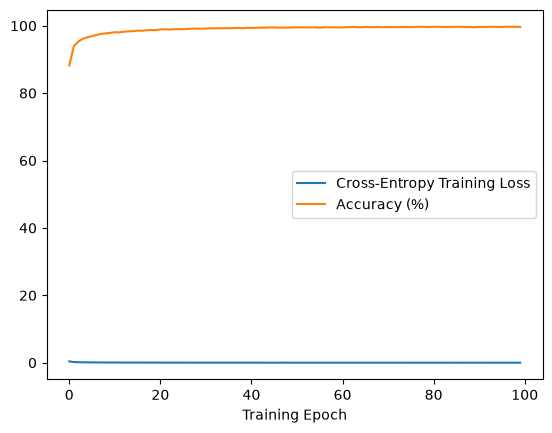

In [19]:
plt.plot(costs, label = 'Cross-Entropy Training Loss')
plt.plot(accuracies*100, label = 'Accuracy (%)')
plt.xlabel('Training Epoch')
plt.legend()
plt.show()

In [20]:
def activation_hidden(Z):
    """ ReLU activation function for hidden layers """
    return np.maximum(0, Z)

def activation_output(z):
    """ softmax activation function for the final output layer """
    shifted = z - np.max(z, axis=0, keepdims=True)
    exp_z = np.exp(shifted)
    return exp_z / np.sum(exp_z, axis=0, keepdims=True)

def accuracy(empirical, true):
    predictions = np.argmax(empirical, axis = 0)
    num_correct = np.sum(predictions == true)
    percent_correct = num_correct / len(predictions)
    return percent_correct

def digit_accuracy(empirical, true, digit):
    predictions = np.argmax(empirical, axis = 0)
    percent_correct = np.mean(predictions[true == digit] == digit)
    return percent_correct
    
def cross_entropy_loss(empirical, true):
    shifted = empirical - np.max(empirical, axis=0, keepdims=True)
    log_probs = shifted - np.log(
        np.sum(np.exp(shifted), axis=0, keepdims=True)
    )
    return -np.sum(true * log_probs) / true.shape[1] 

In [21]:
A_previous = x_test_scaled
for k in range(L):
    Z = weights[k]@A_previous + biases[k]
    if k == L - 1:
        A_previous = activation_output(Z)
    else:
        A_previous = activation_hidden(Z)

test_loss = cross_entropy_loss(Z, y_test_one_hot)
test_accuracy = accuracy(A_previous, y_test)
print(f'Test accuracy is {test_accuracy*100}%')
print(f'Training accuracy in last epoch is {accuracies[-1]*100}%')
print(f'Test loss is {test_loss}')
print(f'Training loss in last epoch is {costs[-1]}')


Test accuracy is 97.58%
Training accuracy in last epoch is 99.638%
Test loss is 0.390515526803929
Training loss in last epoch is 0.010114489732455696


In [22]:
for x in range(0, 10):
    print(f'Accuracy for {x} is {round(digit_accuracy(A_previous, y_test, x)*100, 1)}%')

Accuracy for 0 is 98.8%
Accuracy for 1 is 99.3%
Accuracy for 2 is 97.7%
Accuracy for 3 is 98.3%
Accuracy for 4 is 97.6%
Accuracy for 5 is 95.7%
Accuracy for 6 is 97.8%
Accuracy for 7 is 96.7%
Accuracy for 8 is 96.7%
Accuracy for 9 is 96.8%


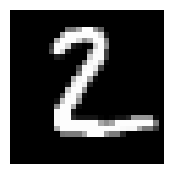

Image 1: predicted digit = 2


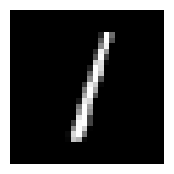

Image 2: predicted digit = 1


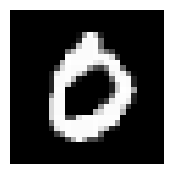

Image 3: predicted digit = 0


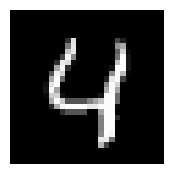

Image 4: predicted digit = 4


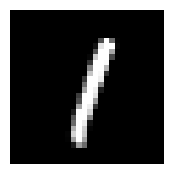

Image 5: predicted digit = 1


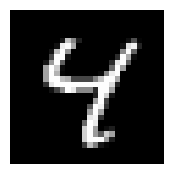

Image 6: predicted digit = 4


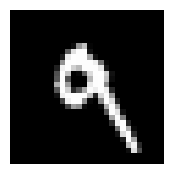

Image 7: predicted digit = 9


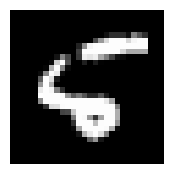

Image 8: predicted digit = 5


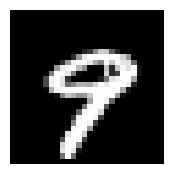

Image 9: predicted digit = 9


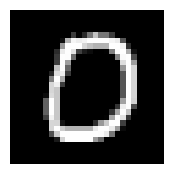

Image 10: predicted digit = 0


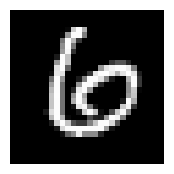

Image 11: predicted digit = 6


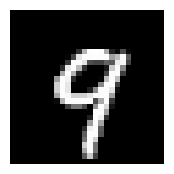

Image 12: predicted digit = 9


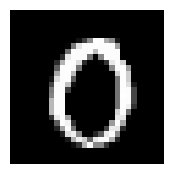

Image 13: predicted digit = 0


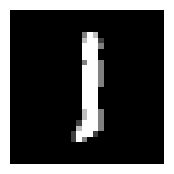

Image 14: predicted digit = 1


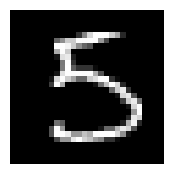

Image 15: predicted digit = 5


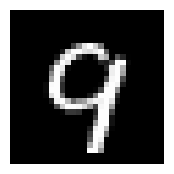

Image 16: predicted digit = 9


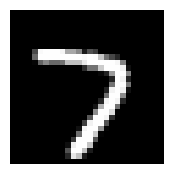

Image 17: predicted digit = 7


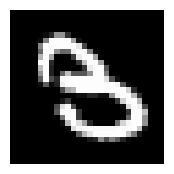

Image 18: predicted digit = 3


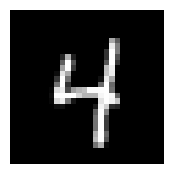

Image 19: predicted digit = 4


In [24]:
image_indices = range(1,20)  # Zero-based indices in the test set.

for i in image_indices:
    plt.figure(figsize=(2, 2))
    plt.imshow(x_test[:, i].reshape(image_size, image_size), cmap="gray")
    plt.axis("off")
    plt.show()
    print(f"Image {i}: predicted digit = {np.argmax(A_previous[:, i])}")
